# Predicting House Prices with Linear Regression
**Objective:** Build and evaluate a linear regression model that predicts house prices from features such as area, location, rooms and age.

**Tech stack:** Python, pandas, scikit-learn, matplotlib, seaborn

> **Note:** `house_prices.csv` is a practice dataset. For your final submission, repeat the steps on a real dataset from Kaggle (search "House Prices: Advanced Regression Techniques" or "Ames Housing"). You will need to adjust column names.

## 0. Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

## 1. Load data and EDA
_Checklist: null check, descriptive statistics, distribution of the target (price)_

In [3]:
df = pd.read_csv("house_prices.csv")
print("Shape:", df.shape)
df.head()

Shape: (1500, 8)


,Area_sqft,Bedrooms,Bathrooms,Age_years,Garage_Spaces,Location,Condition,Price
0,1876.0,3,2.0,25,1,Rural,Average,294600.0
1,916.0,1,NaN,59,0,Suburb,Good,174500.0
2,1361.0,2,2.0,57,1,Rural,Good,194400.0
3,2397.0,4,2.0,49,1,Downtown,Average,372200.0
4,1137.0,2,2.0,49,1,Suburb,Excellent,237800.0


In [4]:
print("Nulls per column:")
print(df.isnull().sum())
print()
df.describe().round(1)

Nulls per column:
Area_sqft        45
Bedrooms          0
Bathrooms        60
Age_years         0
Garage_Spaces     0
Location          0
Condition        75
Price             0
dtype: int64



,Area_sqft,Bedrooms,Bathrooms,Age_years,Garage_Spaces,Price
count,1455.0,1500.0,1440.0,1500.0,1500.0,1500.0
mean,1836.3,2.8,2.1,29.5,1.1,342422.5
std,549.8,1.2,0.9,17.3,0.7,93908.1
min,500.0,1.0,1.0,0.0,0.0,75900.0
25%,1446.5,2.0,1.0,15.0,1.0,277825.0
50%,1822.0,3.0,2.0,29.0,1.0,342850.0
75%,2208.0,4.0,3.0,44.0,2.0,405775.0
max,3725.0,6.0,5.0,59.0,2.0,640600.0


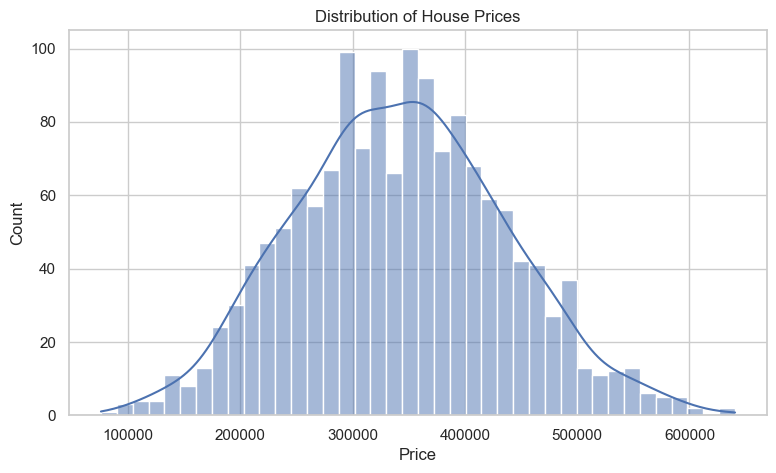

Skewness of Price: 0.12


In [5]:
sns.histplot(df["Price"], bins=40, kde=True)
plt.title("Distribution of House Prices")
plt.show()
print("Skewness of Price:", round(df["Price"].skew(), 2))

**Observation:** _Write 2-3 sentences about what this output shows._

## 2. Feature selection discussion
_Checklist: which features are likely predictors, and why_

_Write your reasoning here. For each feature, say whether you expect it to raise or lower price, and why. For example:_
- **Area_sqft:** _bigger houses usually cost more because..._
- **Age_years:** ...
- **Location:** ...
- **Condition:** ...

## 3. Handle missing values and encode categorical features
_Checklist: missing values, One-Hot Encoding_

In [6]:
# Numeric columns -> median; categorical -> mode
for col in ["Area_sqft", "Bathrooms"]:
    df[col] = df[col].fillna(df[col].median())
df["Condition"] = df["Condition"].fillna(df["Condition"].mode()[0])

print("Nulls left:", df.isnull().sum().sum())

Nulls left: 0


**Justification:** _Why median for numeric columns and mode for categorical ones?_

In [7]:
# One-Hot Encoding (drop_first avoids redundant columns)
df_encoded = pd.get_dummies(df, columns=["Location", "Condition"], drop_first=True, dtype=int)
df_encoded.head()

,Area_sqft,Bedrooms,Bathrooms,Age_years,Garage_Spaces,Price,Location_Rural,Location_Suburb,Location_Waterfront,Condition_Excellent,Condition_Good,Condition_Poor
0,1876.0,3,2.0,25,1,294600.0,1,0,0,0,0,0
1,916.0,1,2.0,59,0,174500.0,0,1,0,0,1,0
2,1361.0,2,2.0,57,1,194400.0,1,0,0,0,1,0
3,2397.0,4,2.0,49,1,372200.0,0,0,0,0,0,0
4,1137.0,2,2.0,49,1,237800.0,0,1,0,1,0,0


## 4. Correlation heatmap
_Checklist: which features are most correlated with price_

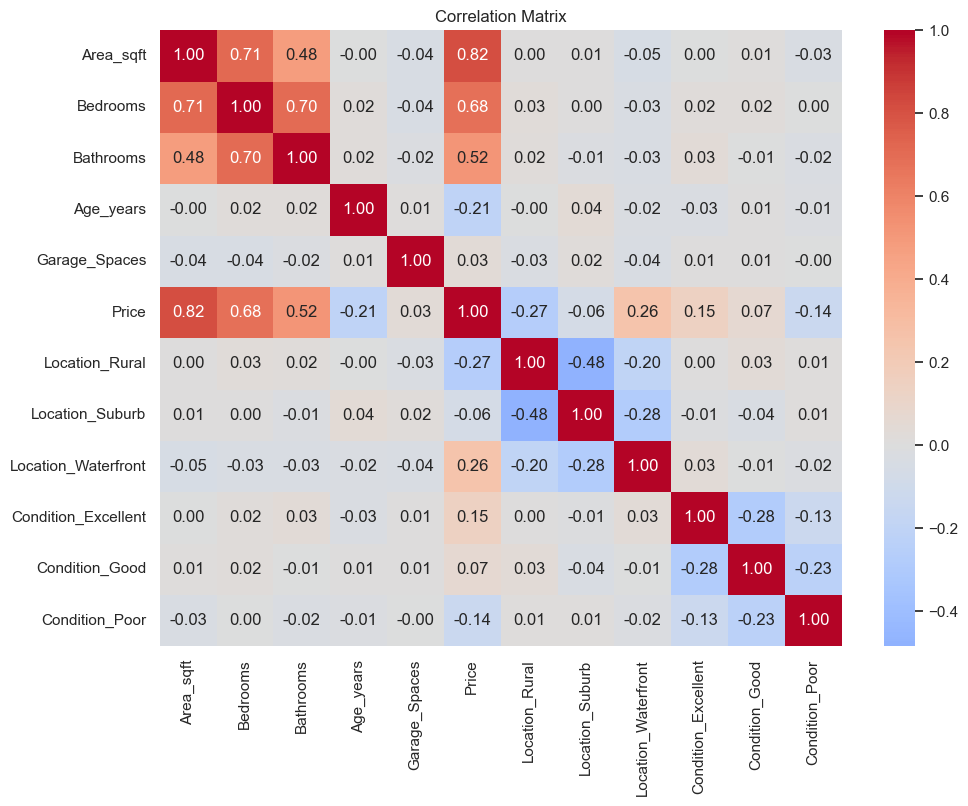

Price                  1.00
Area_sqft              0.82
Bedrooms               0.68
Bathrooms              0.52
Location_Waterfront    0.26
Condition_Excellent    0.15
Condition_Good         0.07
Garage_Spaces          0.03
Location_Suburb       -0.06
Condition_Poor        -0.14
Age_years             -0.21
Location_Rural        -0.27
Name: Price, dtype: float64


In [8]:
corr = df_encoded.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

print(corr["Price"].sort_values(ascending=False).round(2))

**Observation:** _Write 2-3 sentences about what this output shows._

## 5. Train/test split (80/20)

In [9]:
X = df_encoded.drop(columns="Price")
y = df_encoded["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1200, 11)  Test: (300, 11)


## 6. Train the Linear Regression model

In [10]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## 7. Evaluate the model
_Checklist: MSE, RMSE, R-squared_

In [11]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MSE:  {mse:,.0f}")
print(f"RMSE: {rmse:,.0f}")
print(f"R2:   {r2:.3f}")

MSE:  664,948,199
RMSE: 25,787
R2:   0.929


**Interpretation:** _RMSE is in the same unit as price. What does that number mean for a typical prediction? What does the R-squared tell you about how much of the price variation the model explains?_

## 8. Actual vs. predicted prices
_Checklist: scatter plot (closer to the diagonal = better)_

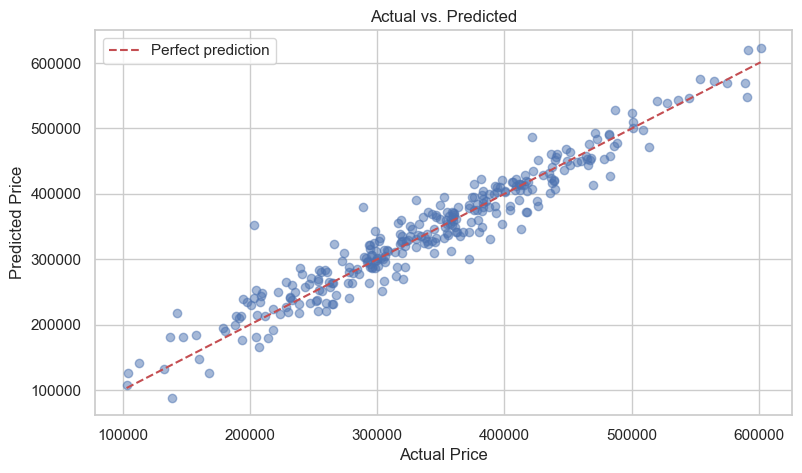

In [12]:
plt.scatter(y_test, y_pred, alpha=0.5)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs. Predicted")
plt.legend()
plt.show()

**Observation:** _Write 2-3 sentences about what this output shows._

## 9. Residual plot
_Checklist: residuals should be randomly scattered with no pattern_

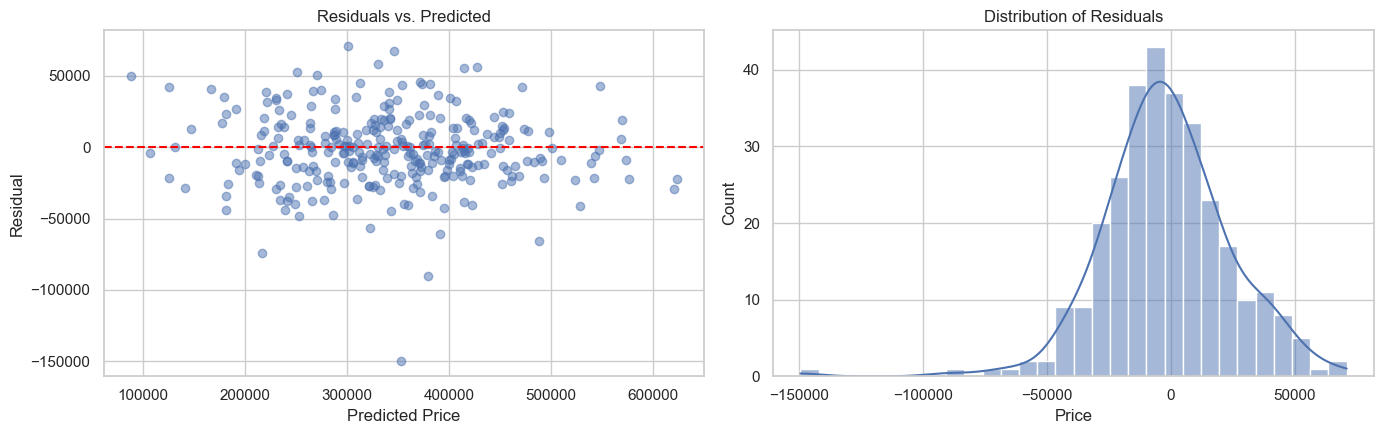

In [13]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(y_pred, residuals, alpha=0.5)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted Price")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs. Predicted")

sns.histplot(residuals, bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Residuals")
plt.tight_layout()
plt.show()

**Observation:** _Do you see any pattern, such as a curve or a funnel shape? What would a pattern mean for the model?_

## 10. Coefficient analysis
_Checklist: which features have the highest positive/negative impact on price_

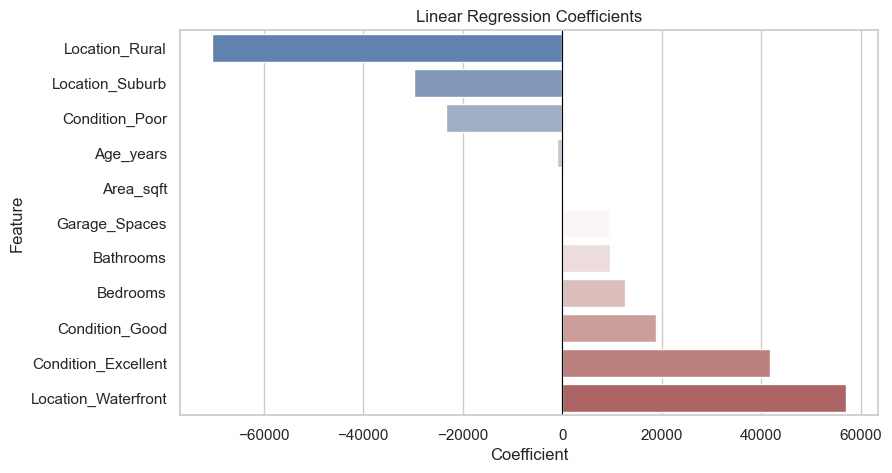

,Feature,Coefficient
5,Location_Rural,-70375.6
6,Location_Suburb,-29862.2
10,Condition_Poor,-23260.0
3,Age_years,-1068.5
0,Area_sqft,116.9
4,Garage_Spaces,9466.5
2,Bathrooms,9692.7
1,Bedrooms,12575.7
9,Condition_Good,18825.0
8,Condition_Excellent,41795.7


In [14]:
coef = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_})
coef = coef.sort_values("Coefficient")

sns.barplot(data=coef, x="Coefficient", y="Feature", hue="Feature", palette="vlag", legend=False)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Linear Regression Coefficients")
plt.show()
coef.round(1)

**Interpretation:** _Each coefficient is the change in price when that feature rises by one unit and everything else stays the same. Explain two of them in plain words._

## 11. (Bonus) Compare with Ridge and Lasso
_Checklist: regularised models_

In [15]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

results = []
for name, m in [("Linear", LinearRegression()),
                ("Ridge", Ridge(alpha=1.0)),
                ("Lasso", Lasso(alpha=1.0))]:
    m.fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    results.append({"Model": name,
                    "RMSE": np.sqrt(mean_squared_error(y_test, p)),
                    "R2": r2_score(y_test, p)})

pd.DataFrame(results).round(3)

,Model,RMSE,R2
0,Linear,25786.590,0.929
1,Ridge,25780.168,0.929
2,Lasso,25786.187,0.929


**Observation:** _Which model is best? Why might regularisation make little difference here?_

## 12. Conclusion
_Summarise in 4-6 sentences: how well does the model predict, which features matter most, what are its limits, and how could you improve it?_